<a href="https://colab.research.google.com/github/ounissinour/PolypVision/blob/milestone-2-final-test/notebooks/03b_PolypPVT_Final_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2 – final test of the validation-selected Polyp-PVT

**PolypVision** · Nour Ounissi (RSPN69), Taha Mersni (K1TO74), Baha Amar (ZXQA2V)

`03_PolypPVT_Retraining.ipynb` trained six configurations and **locked** the winner on validation only:
`size_288` (structure loss, no augmentation, 288 × 288), epoch 100, validation mean Dice 0.9196 / IoU 0.8678
(`results/validation_selection.json`). Its test evaluation never produced numbers: the overlap guard stopped
it (49 test images look like training images) and the last attempt crashed with `NameError: json`.

This notebook finishes Milestone 2: it scores the `size_288` model **once** on the five official test sets.
Nothing is re-selected or re-tuned here. The locked epoch-100 file itself could not be recovered (the copy in the
shared Drive folder is an epoch-19 save), so by default (`MODE = "retrain"`) `size_288` is first re-trained with
Baha's identical recipe and its best epoch is again chosen on validation only.

**About the 49 flagged images.** Most are CVC-ClinicDB test frames whose neighbouring video frames are in the
training set. This is a property of the *official benchmark split* that both papers and every comparison table
use (the authors' 0.937 on ClinicDB is measured the same way), not a leak created by our pipeline. So we report
two numbers per test set:

* **full** – all images, directly comparable with the papers and with Milestone 1;
* **excluding flagged** – without the 49 near-duplicate candidates, to show how much the overlap matters.

| Step | What happens |
|---|---|
| 1 | Settings, packages, official Polyp-PVT code (pinned), Baha's `m2_pipeline.py` and result files from the repository |
| 2 | Data: test sets (and the training set, only if the checkpoint has to be re-created) |
| 3 | The locked checkpoint: load it from Drive, check it **is** `size_288` and re-check its validation score; if it is not on this Drive, optionally re-train it with the identical recipe |
| 4 | One test evaluation: per-image and per-dataset mean Dice / IoU (256 thresholds, as the papers and Milestone 1), full and excluding flagged |
| 5 | Comparison with the authors' Polyp-PVT and PraNet (Milestone 1 per-image scores, same metric) |
| 6 | Figures and saving the results |

## 1. Settings

In [1]:
import os
BRANCH = "milestone-2-final-test"   # repository branch that holds m2_pipeline.py and notebooks/results
REPO_RAW = f"https://raw.githubusercontent.com/ounissinour/PolypVision/{BRANCH}"
PVT_COMMIT = "cd71fbf9fcd8c32cc0f33699f4e0186073c64dc4"

# "retrain": re-train size_288 here with Baha's identical recipe (~1.5 h on a T4), then test it.
# "locked":  test the checkpoint locked in 03_PolypPVT_Retraining.ipynb (needs Baha's real epoch-100 best.pt
#            at LOCKED_CHECKPOINT; the copy in the shared folder on 18 Nov 2026 was an epoch-19 save).
MODE = "retrain"
LOCKED_CHECKPOINT = "/content/drive/MyDrive/PolypVision_M2/runs/size_288/best.pt"

from google.colab import drive
drive.mount("/content/drive")
WORK = "/content/drive/MyDrive/PolypVision_retrain"   # our own folder: final model (~100 MB) + results; Baha's files are never written
RUNS = "/content/runs"     # training checkpoints on the local Colab disk (last.pt ~300 MB is re-saved every epoch;
                           # on Drive that would fill the storage/trash). The final model is copied to WORK at the end.
CACHE = "/content/cache"   # downloaded zips (local, re-downloaded in seconds)
DATA = "/content/polyp_data"
OUT = f"{WORK}/final_test"
for d in [WORK, RUNS, CACHE, DATA, OUT]:
    os.makedirs(d, exist_ok=True)
os.environ.update(WORK=WORK, CACHE=CACHE, DATA=DATA, REPO_RAW=REPO_RAW, PVT_COMMIT=PVT_COMMIT)
print("mode:", MODE, "| results folder:", WORK)

Mounted at /content/drive
mode: retrain | results folder: /content/drive/MyDrive/PolypVision_retrain


In [2]:
%pip -q install gdown pysodmetrics timm tabulate

In [3]:
%%bash
set -e
cd /content
[ -d Polyp-PVT ] || git clone -q --filter=blob:none https://github.com/DengPingFan/Polyp-PVT
git -C Polyp-PVT checkout -q --detach $PVT_COMMIT && git -C Polyp-PVT log -1 --format='Polyp-PVT %h %cd'
mkdir -p /content/repo
for f in src/training/m2_pipeline.py notebooks/results/validation_selection.json notebooks/results/validation_summary.csv \
         notebooks/results/training_split_manifest.csv notebooks/results/overlap_audit_candidates.csv \
         milestone1/results/PraNet_per_image.csv milestone1/results/Polyp-PVT_per_image.csv; do
  wget -q -O /content/repo/$(basename $f) $REPO_RAW/$f || { echo "missing $f on branch" >&2; exit 1; }
done
cp /content/repo/m2_pipeline.py /content/m2_pipeline.py
ls -l /content/repo

Polyp-PVT cd71fbf Wed Nov 1 14:41:31 2023 +0800
total 476
-rw-r--r-- 1 root root  24485 Nov 18 13:25 m2_pipeline.py
-rw-r--r-- 1 root root   3243 Nov 18 13:25 overlap_audit_candidates.csv
-rw-r--r-- 1 root root  86598 Nov 18 13:25 Polyp-PVT_per_image.csv
-rw-r--r-- 1 root root  82872 Nov 18 13:25 PraNet_per_image.csv
-rw-r--r-- 1 root root 272916 Nov 18 13:25 training_split_manifest.csv
-rw-r--r-- 1 root root    406 Nov 18 13:25 validation_selection.json
-rw-r--r-- 1 root root    591 Nov 18 13:25 validation_summary.csv


## 2. Data and backbone

Same Google Drive links as Milestone 1 and `03_PolypPVT_Retraining.ipynb`. The PVTv2-B2 backbone file is needed
because the `PolypPVT` constructor loads it; its weights are then replaced by the checkpoint.

In [4]:
%%bash
set -euo pipefail
cd $CACHE
[ -f TestDataset.zip ] || gdown -q 1Y2z7FD5p5y31vkZwQQomXFRB0HutHyao -O TestDataset.zip
if [ ! -f pvt_v2_b2.pth ]; then
  gdown -q --folder 1Eu8v9vMRvt-dyCH0XSV2i77lAd62nPXV -O backbone_download
  find backbone_download -name 'pvt_v2_b2*.pth' -exec cp {} pvt_v2_b2.pth \; -quit
  rm -rf backbone_download
fi
rm -rf $DATA/TestDataset && unzip -q -o TestDataset.zip -d $DATA && rm -rf $DATA/__MACOSX
mkdir -p /content/Polyp-PVT/pretrained_pth && cp -n pvt_v2_b2.pth /content/Polyp-PVT/pretrained_pth/
for d in Kvasir:100 CVC-ClinicDB:62 CVC-ColonDB:380 ETIS-LaribPolypDB:196 CVC-300:60; do
  n=$(ls $DATA/TestDataset/${d%%:*}/images | wc -l); printf '%-18s %4s images (expected %s)\n' ${d%%:*} $n ${d##*:}
  [ $n -eq ${d##*:} ] || { echo "test set incomplete" >&2; exit 1; }
done

Kvasir              100 images (expected 100)
CVC-ClinicDB         62 images (expected 62)
CVC-ColonDB         380 images (expected 380)
ETIS-LaribPolypDB   196 images (expected 196)
CVC-300              60 images (expected 60)


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


## 3. The size_288 model

**`MODE = "retrain"`** (default): the checkpoint locked by Baha could not be recovered (the file in the shared
folder is an epoch-19 save, validation Dice 0.908, not the locked epoch 100 / 0.9196). So `size_288` is re-trained
here with Baha's own `train_experiment` and identical settings: same split manifest (1360 train / 90 validation),
seed 2026, 100 epochs, batch 8, AdamW 1e-4, weight decay 1e-4, gradient clipping 0.5, AMP, best epoch chosen on
validation. GPU training is not bit-for-bit deterministic, so this is a faithful **re-run**, not the identical file.
About 1.5 h on a T4: keep the tab open and the laptop awake. Training checkpoints stay on the local Colab disk;
the final model and its epoch log are copied to `MyDrive/PolypVision_retrain`.

**`MODE = "locked"`**: tests Baha's locked file instead; it must re-score to the locked validation Dice 0.9196.

Either way the checkpoint is checked (config must be `size_288`; re-scoring validation must give back its stored
score) before any test image is touched.

In [5]:
import json, sys, hashlib
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import torch.nn.functional as F
sys.path.insert(0, "/content")
import m2_pipeline as m2

assert torch.cuda.is_available(), "Select Runtime > Change runtime type > GPU."
DEVICE = torch.device("cuda")
lock = json.loads(Path("/content/repo/validation_selection.json").read_text())
LOCKED = {"name": "size_288", "size": 288, "loss": "structure", "augmentation": False}
assert lock["selected_experiment"] == LOCKED["name"], lock
print(json.dumps(lock, indent=2))

def make_model():
    os.chdir("/content/Polyp-PVT")
    from lib.pvt import PolypPVT
    return PolypPVT()

manifest = pd.read_csv("/content/repo/training_split_manifest.csv")
print(manifest.groupby(["split", "source"]).size().unstack(fill_value=0))

# training images: needed to train and to re-check the validation score
train_zip = Path(CACHE) / "TrainDataset.zip"
if not train_zip.exists():
    os.system(f"gdown -q 1YiGHLw4iTvKdvbT6MgwO9zcCv8zJ_Bnb -O '{train_zip}'")
if not Path(DATA, "TrainDataset", "image").is_dir():
    os.system(f"unzip -q -o '{train_zip}' -d {DATA} && rm -rf {DATA}/__MACOSX")

import shutil
if MODE == "locked":
    CHECKPOINT = LOCKED_CHECKPOINT
    checkpoint_source = "locked checkpoint from 03_PolypPVT_Retraining.ipynb"
    if not Path(CHECKPOINT).exists():
        raise FileNotFoundError(f"{CHECKPOINT} not found (shortcut Baha's PolypVision_M2 folder into MyDrive), or use MODE = 'retrain'.")
elif MODE == "retrain":
    checkpoint_source = ("re-trained here: size_288 with Baha's identical recipe (same split manifest, seed 2026, 100 epochs); "
                         "the locked epoch-100 file could not be recovered")
    runtime = {"torch": torch.__version__, "gpu": torch.cuda.get_device_name(0)}
    m2.train_experiment(LOCKED, make_model, manifest[manifest.split == "train"].reset_index(drop=True),
                        manifest[manifest.split == "val"].reset_index(drop=True), DATA, RUNS, runtime,
                        seed=2026, epochs=100, batch_size=8, learning_rate=1e-4, weight_decay=1e-4,
                        grad_clip=0.5, amp=True, resume=True)
    CHECKPOINT = f"{RUNS}/size_288/best.pt"
    for name, target in [("best.pt", "size_288_best.pt"), ("epochs.csv", "size_288_epochs.csv"), ("config.json", "size_288_config.json")]:
        shutil.copy(f"{RUNS}/size_288/{name}", f"{WORK}/{target}")
    history = pd.read_csv(f"{RUNS}/size_288/epochs.csv")
    best = history.sort_values(["val_mean_dice", "val_mean_iou"], ascending=False).iloc[0]
    print(f"re-train finished: best epoch {int(best.epoch)}, validation Dice {best.val_mean_dice:.4f} / IoU {best.val_mean_iou:.4f} "
          f"(Baha's locked run: epoch 100, 0.9196 / 0.8678); {history.epoch_seconds.sum()/60:.0f} min")
else:
    raise ValueError(MODE)
print("checkpoint source:", checkpoint_source)

{
  "selected_experiment": "size_288",
  "selected_checkpoint": "MyDrive/PolypVision_M2/runs/size_288/best.pt",
  "best_epoch": 100,
  "selection_rule": "highest validation dynamic mean Dice; validation dynamic mean IoU tie-break",
  "validation_mean_dice": 0.9196323032297294,
  "validation_mean_iou": 0.8678036419606217,
  "locked_at_utc": "2026-11-17T23:05:41.641630+00:00",
  "test_evaluated": false
}
source  CVC-ClinicDB  Kvasir
split                       
train            550     810
val                0      90


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/content/Polyp-PVT/lib/pvtv2.py:387: UserWarning: Overwriting pvt_v2_b0 in registry with lib.pvtv2.pvt_v2_b0. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/content/Polyp-PVT/lib/pvtv2.py:397: UserWarning: Overwriting pvt_v2_b1 in registry with lib.pvtv2.pvt_v2_b1. This is because the name being registered conflicts with an existing name. Please check if this is not ex

size_288: epoch 1/100, loss=2.5394, val Dice=0.8222, val IoU=0.7257, 0.8 min
size_288: epoch 2/100, loss=1.6045, val Dice=0.8636, val IoU=0.7906, 0.7 min
size_288: epoch 3/100, loss=1.3228, val Dice=0.8776, val IoU=0.8066, 0.7 min
size_288: epoch 4/100, loss=1.1239, val Dice=0.8874, val IoU=0.8278, 0.7 min
size_288: epoch 5/100, loss=0.9256, val Dice=0.8858, val IoU=0.8227, 0.7 min
size_288: epoch 6/100, loss=0.8104, val Dice=0.8949, val IoU=0.8353, 0.7 min
size_288: epoch 7/100, loss=0.6919, val Dice=0.9036, val IoU=0.8483, 0.7 min
size_288: epoch 8/100, loss=0.6017, val Dice=0.9065, val IoU=0.8529, 0.7 min
size_288: epoch 9/100, loss=0.5283, val Dice=0.9071, val IoU=0.8508, 0.7 min
size_288: epoch 10/100, loss=0.4628, val Dice=0.8964, val IoU=0.8382, 0.7 min
size_288: epoch 11/100, loss=0.4227, val Dice=0.8987, val IoU=0.8441, 0.7 min
size_288: epoch 12/100, loss=0.3846, val Dice=0.8898, val IoU=0.8321, 0.7 min
size_288: epoch 13/100, loss=0.3471, val Dice=0.9073, val IoU=0.8530, 0.7

In [6]:
ckpt = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
assert ckpt["config"] == LOCKED, f"not the locked run: {ckpt['config']}"
sha = hashlib.sha256(Path(CHECKPOINT).read_bytes()).hexdigest()
model = make_model().to(DEVICE)
model.load_state_dict(ckpt["model"])
model.eval()
print(f"config {ckpt['config']} | epoch {ckpt['epoch']} | stored val Dice {ckpt['val_mean_dice']:.6f} | sha256 {sha[:16]}…")

val_rows = manifest[manifest.split == "val"].reset_index(drop=True)
if Path(DATA, "TrainDataset", "image").is_dir():
    val_dice, val_iou = m2.validate(model, val_rows, DATA, LOCKED["size"], DEVICE)
    print(f"re-scored validation: Dice {val_dice:.6f} / IoU {val_iou:.6f}  (stored {ckpt['val_mean_dice']:.6f} / {ckpt['val_mean_iou']:.6f})")
    assert abs(val_dice - ckpt["val_mean_dice"]) < 1e-4, "checkpoint does not reproduce its validation score"
else:
    print("TrainDataset not unpacked: validation re-check skipped (the stored score is printed above)")
if checkpoint_source.startswith("locked"):
    assert abs(ckpt["val_mean_dice"] - lock["validation_mean_dice"]) < 1e-6, "this is not the locked checkpoint"

config {'name': 'size_288', 'size': 288, 'loss': 'structure', 'augmentation': False} | epoch 56 | stored val Dice 0.918441 | sha256 5f3ef4c86894deeb…


/content/Polyp-PVT/lib/pvt.py:91: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  edge = F.upsample(edge, (x.size()[-2], x.size()[-1]))


re-scored validation: Dice 0.918441 / IoU 0.867624  (stored 0.918441 / 0.867624)


## 4. One test evaluation

Prediction exactly as in Baha's `evaluate_locked_test` (and validation): resize to 288 with OpenCV, ImageNet
normalisation, P1 + P2, bilinear upsampling to the mask size, sigmoid, ×255. Scoring exactly as Milestone 1:
pysodmetrics `FmeasureV2`, 256 thresholds, sample-based mean Dice / IoU (Dice@0.5 for reference). Scores are kept
per image, so the "excluding flagged" numbers are simply the mean over the remaining images (the 256-threshold
mean is linear in the images, so this equals scoring the reduced set).

In [7]:
from py_sod_metrics import DICEHandler, FmeasureV2, IOUHandler
TEST = ["Kvasir", "CVC-ClinicDB", "CVC-ColonDB", "ETIS-LaribPolypDB", "CVC-300"]
flagged = pd.read_csv("/content/repo/overlap_audit_candidates.csv")
flagged_keys = set(zip(flagged.dataset, flagged.test_stem.astype(str)))
print("flagged per dataset:", flagged.dataset.value_counts().to_dict())

@torch.no_grad()
def predict(model, image_bgr, size, out_hw):
    image = cv2.resize(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB), (size, size), interpolation=cv2.INTER_LINEAR)
    x = (image.astype(np.float32) / 255.0 - m2.IMAGENET_MEAN) / m2.IMAGENET_STD
    p1, p2 = model(torch.from_numpy(np.ascontiguousarray(x)).permute(2, 0, 1)[None].to(DEVICE))
    prob = torch.sigmoid(F.interpolate(p1 + p2, size=out_hw, mode="bilinear", align_corners=False))[0, 0]
    return np.clip(prob.float().cpu().numpy() * 255, 0, 255).astype(np.uint8)

rows = []
for dataset in TEST:
    root = Path(DATA, "TestDataset", dataset)
    images = m2._index_by_stem(root / "images", m2.IMAGE_EXTENSIONS)
    masks = m2._index_by_stem(root / "masks", m2.MASK_EXTENSIONS)
    assert set(images) == set(masks) and len(images) == m2.TEST_COUNTS[dataset]
    dice = DICEHandler(with_dynamic=True, with_adaptive=False, with_binary=True, sample_based=True)
    iou = IOUHandler(with_dynamic=True, with_adaptive=False, with_binary=True, sample_based=True)
    metric = FmeasureV2(metric_handlers={"dice": dice, "iou": iou})
    stems = sorted(images)
    for stem in stems:
        gt = cv2.imread(str(masks[stem]), cv2.IMREAD_GRAYSCALE)
        pred = predict(model, cv2.imread(str(images[stem])), LOCKED["size"], gt.shape)
        metric.step(pred=pred, gt=((gt > 127) * 255).astype(np.uint8), normalize=True)
    rows.append(pd.DataFrame({
        "dataset": dataset, "stem": stems,
        "dice": np.mean(dice.dynamic_results, axis=1), "iou": np.mean(iou.dynamic_results, axis=1),
        "dice_0.5": np.ravel(dice.binary_results), "iou_0.5": np.ravel(iou.binary_results),
    }))
    print(f"{dataset:18s} n={len(stems):4d} meanDice={rows[-1].dice.mean():.4f}")
per_image = pd.concat(rows, ignore_index=True)
per_image["flagged"] = [(d, str(s)) in flagged_keys for d, s in zip(per_image.dataset, per_image.stem)]
assert per_image.flagged.sum() == len(flagged), "flagged list does not match the test file names"
per_image.to_csv(f"{OUT}/size_288_test_per_image.csv", index=False)

def summarise(df, label):
    out = []
    for dataset in TEST:
        g = df[df.dataset == dataset]
        clean = g[~g.flagged]
        out.append({"model": label, "dataset": dataset, "n": len(g), "meanDice": g.dice.mean(), "meanIoU": g.iou.mean(),
                    "Dice@0.5": g["dice_0.5"].mean(), "n_excl_flagged": len(clean),
                    "meanDice_excl_flagged": clean.dice.mean(), "meanIoU_excl_flagged": clean.iou.mean()})
    return pd.DataFrame(out)

ours = summarise(per_image, "Polyp-PVT size_288, ours (re-trained, validation-selected)")
ours.to_csv(f"{OUT}/final_test_metrics.csv", index=False)
print(ours.round(4).to_string(index=False))

flagged per dataset: {'CVC-ColonDB': 26, 'CVC-ClinicDB': 20, 'ETIS-LaribPolypDB': 2, 'Kvasir': 1}


/content/Polyp-PVT/lib/pvt.py:91: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  edge = F.upsample(edge, (x.size()[-2], x.size()[-1]))


Kvasir             n= 100 meanDice=0.8994
CVC-ClinicDB       n=  62 meanDice=0.8888
CVC-ColonDB        n= 380 meanDice=0.7823
ETIS-LaribPolypDB  n= 196 meanDice=0.7056
CVC-300            n=  60 meanDice=0.8705
                                                     model           dataset   n  meanDice  meanIoU  Dice@0.5  n_excl_flagged  meanDice_excl_flagged  meanIoU_excl_flagged
Polyp-PVT size_288, ours (re-trained, validation-selected)            Kvasir 100    0.8994   0.8463    0.9023              99                 0.9075                0.8543
Polyp-PVT size_288, ours (re-trained, validation-selected)      CVC-ClinicDB  62    0.8888   0.8350    0.8921              42                 0.8861                0.8312
Polyp-PVT size_288, ours (re-trained, validation-selected)       CVC-ColonDB 380    0.7823   0.7027    0.7851             354                 0.7840                0.7060
Polyp-PVT size_288, ours (re-trained, validation-selected) ETIS-LaribPolypDB 196    0.7056   0.6251    0.7

## 5. Comparison with the authors' Polyp-PVT and PraNet

Milestone 1 stored per-image scores of the authors' released models, computed with the same metric
(`milestone1/results/*_per_image.csv`), so the same "excluding flagged" subsets can be scored for them without
re-running anything. Reminder: the authors' Polyp-PVT checkpoint was chosen **on the test sets** by the official
`Train.py`; ours was chosen on validation only.

In [8]:
def from_m1(path, label):
    df = pd.read_csv(path)
    df["stem"] = df.image.str.rsplit(".", n=1).str[0]
    df = df.rename(columns={"dice_mean_thr": "dice", "iou_mean_thr": "iou"})
    df["flagged"] = [(d, str(s)) in flagged_keys for d, s in zip(df.dataset, df.stem)]
    assert df.flagged.sum() == len(flagged), f"{label}: flagged images not all found"
    return summarise(df, label)

authors = from_m1("/content/repo/Polyp-PVT_per_image.csv", "Polyp-PVT, authors (epoch chosen on test)")
pranet = from_m1("/content/repo/PraNet_per_image.csv", "PraNet, authors")
assert abs(authors.set_index("dataset").loc["CVC-ColonDB", "meanDice"] - 0.808) < 0.001
allres = pd.concat([pranet, authors, ours], ignore_index=True)
allres.to_csv(f"{OUT}/final_comparison_long.csv", index=False)

def wide(col):
    t = allres.pivot(index="model", columns="dataset", values=col)[TEST]
    t["mean of 5"] = t.mean(axis=1)
    return t.loc[[pranet.model[0], authors.model[0], ours.model[0]]]

full, clean = wide("meanDice"), wide("meanDice_excl_flagged")
full.to_csv(f"{OUT}/final_comparison_full.csv"); clean.to_csv(f"{OUT}/final_comparison_excl_flagged.csv")
with open(f"{OUT}/final_comparison.md", "w") as f:
    f.write("Mean Dice, all test images\n\n" + full.round(3).to_markdown() +
            "\n\nMean Dice, excluding the 49 flagged near-duplicate candidates\n\n" + clean.round(3).to_markdown() +
            "\n\nMean IoU, all test images\n\n" + wide("meanIoU").round(3).to_markdown())
print("Mean Dice, all test images\n", full.round(3).to_string(), "\n")
print("Mean Dice, excluding flagged\n", clean.round(3).to_string(), "\n")
print("Mean IoU, all test images\n", wide("meanIoU").round(3).to_string())

Mean Dice, all test images
 dataset                                                     Kvasir  CVC-ClinicDB  CVC-ColonDB  ETIS-LaribPolypDB  CVC-300  mean of 5
model                                                                                                                               
PraNet, authors                                              0.894         0.899        0.712              0.628    0.871      0.801
Polyp-PVT, authors (epoch chosen on test)                    0.917         0.937        0.808              0.787    0.900      0.870
Polyp-PVT size_288, ours (re-trained, validation-selected)   0.899         0.889        0.782              0.706    0.871      0.829 

Mean Dice, excluding flagged
 dataset                                                     Kvasir  CVC-ClinicDB  CVC-ColonDB  ETIS-LaribPolypDB  CVC-300  mean of 5
model                                                                                                                               
PraNet, a

## 6. Figures and record

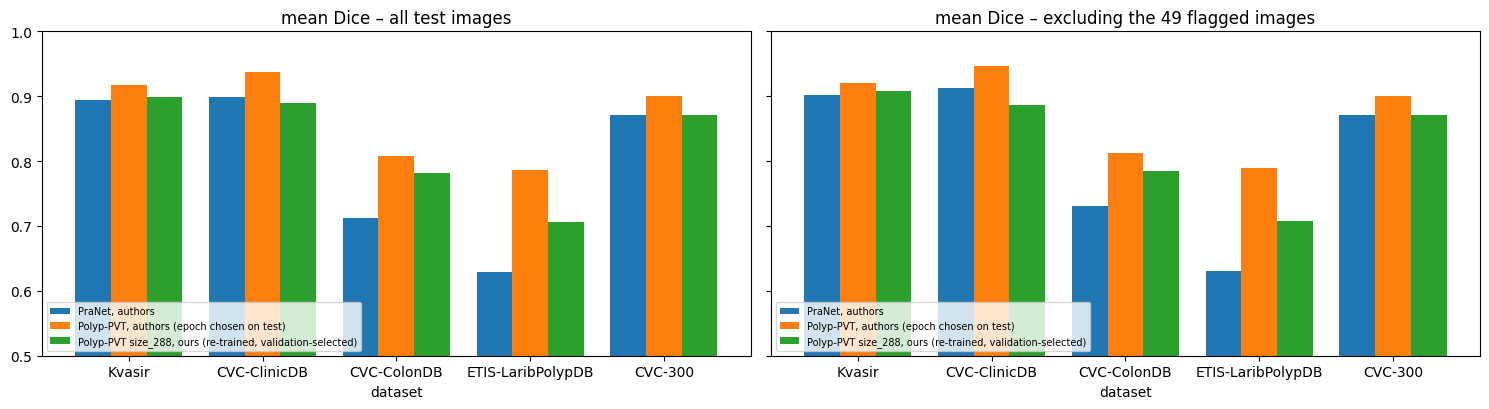

/content/Polyp-PVT/lib/pvt.py:91: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  edge = F.upsample(edge, (x.size()[-2], x.size()[-1]))


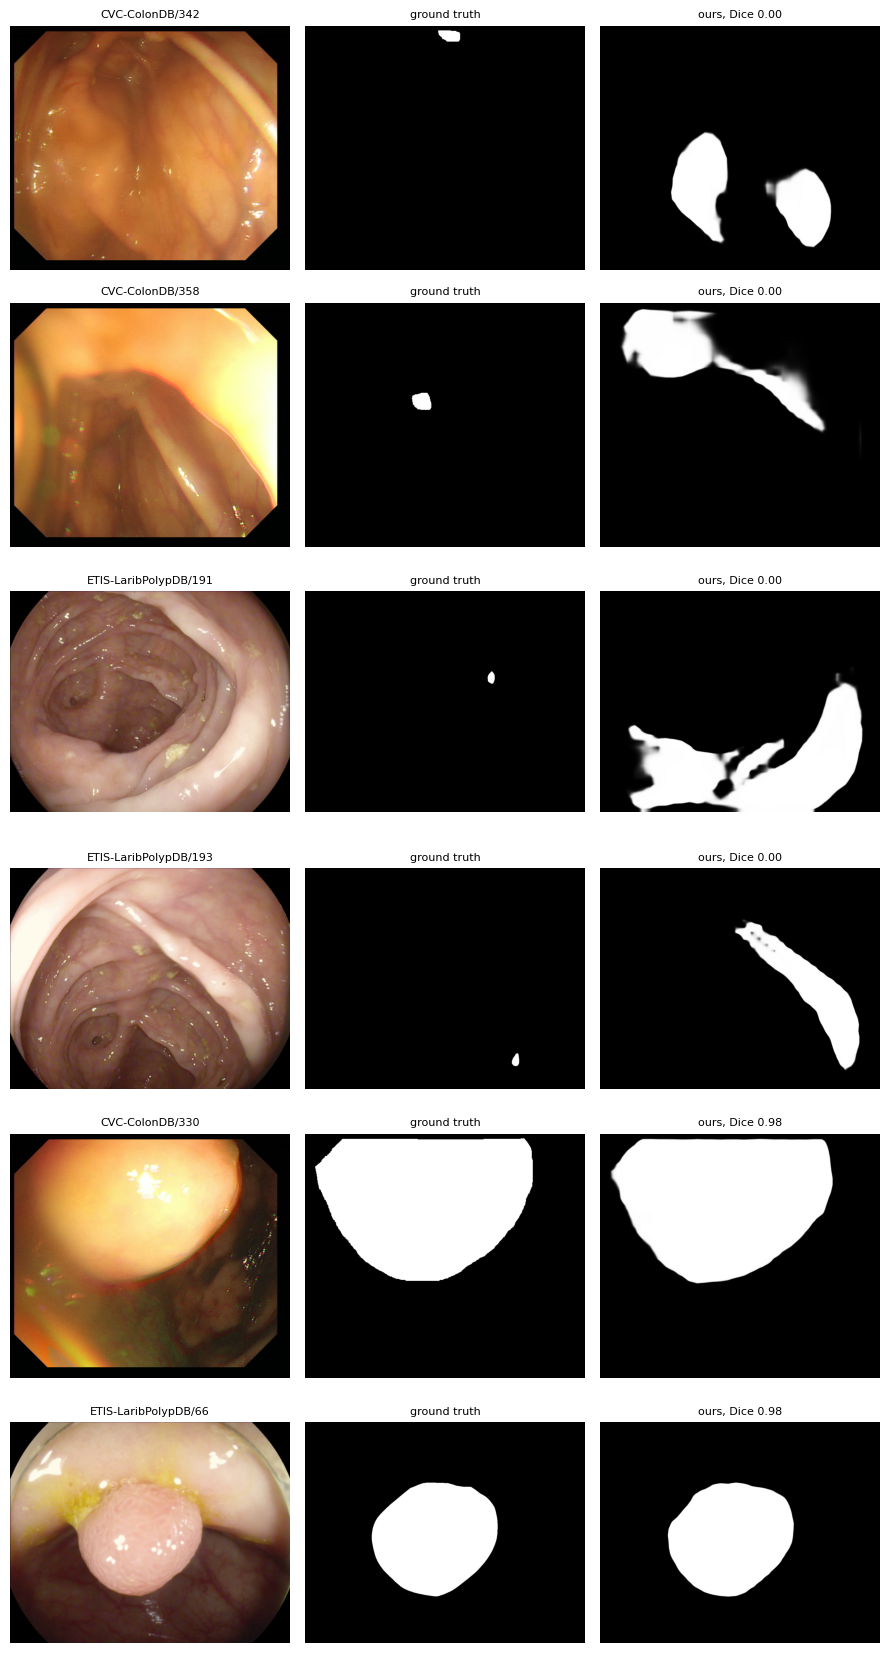

{
  "selected_experiment": "size_288",
  "checkpoint": "/content/runs/size_288/best.pt",
  "checkpoint_sha256": "5f3ef4c86894deeb9ba4b7a85c06fb3ba32e830cea39780b22a0c52bf3107f95",
  "checkpoint_source": "re-trained here: size_288 with Baha's identical recipe (same split manifest, seed 2026, 100 epochs); the locked epoch-100 file could not be recovered",
  "checkpoint_epoch": 56,
  "validation_mean_dice": 0.918440893761584,
  "test_evaluated_once": true,
  "test_evaluated_at_utc": "2026-11-18T14:39:34.082204+00:00",
  "flagged_images_excluded_in_second_table": 49,
  "files": [
    "final_test_metrics.csv",
    "size_288_test_per_image.csv",
    "final_comparison_full.csv",
    "final_comparison_excl_flagged.csv",
    "final_comparison.md",
    "final_comparison.png",
    "examples.png"
  ]
}

Copy the folder /content/drive/MyDrive/PolypVision_retrain/final_test into notebooks/results/final_test/ in the repository.


In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, (t, title) in zip(axes, [(full, "all test images"), (clean, "excluding the 49 flagged images")]):
    t[TEST].T.plot.bar(ax=ax, width=0.8, rot=0)
    ax.set_title(f"mean Dice – {title}"); ax.set_ylim(0.5, 1.0); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT}/final_comparison.png", dpi=150); plt.show()

# hardest and easiest test images for our model (ColonDB and ETIS, the unseen sets)
show = pd.concat([per_image[per_image.dataset == d].nsmallest(2, "dice") for d in ["CVC-ColonDB", "ETIS-LaribPolypDB"]] +
                 [per_image[per_image.dataset == d].nlargest(1, "dice") for d in ["CVC-ColonDB", "ETIS-LaribPolypDB"]])
fig, axes = plt.subplots(len(show), 3, figsize=(9, 2.8 * len(show)))
for ax_row, r in zip(axes, show.itertuples()):
    root = Path(DATA, "TestDataset", r.dataset)
    img = cv2.imread(str(m2._index_by_stem(root / "images", m2.IMAGE_EXTENSIONS)[r.stem]))
    gt = cv2.imread(str(m2._index_by_stem(root / "masks", m2.MASK_EXTENSIONS)[r.stem]), 0)
    pred = predict(model, img, LOCKED["size"], gt.shape)
    for ax, (im, title) in zip(ax_row, [(img[:, :, ::-1], f"{r.dataset}/{r.stem}"), (gt, "ground truth"), (pred, f"ours, Dice {r.dice:.2f}")]):
        ax.imshow(im, cmap=None if im.ndim == 3 else "gray"); ax.set_title(title, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/examples.png", dpi=110); plt.show()

record = {"selected_experiment": "size_288", "checkpoint": CHECKPOINT, "checkpoint_sha256": sha,
          "checkpoint_source": checkpoint_source, "checkpoint_epoch": int(ckpt["epoch"]),
          "validation_mean_dice": float(ckpt["val_mean_dice"]), "test_evaluated_once": True,
          "test_evaluated_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
          "flagged_images_excluded_in_second_table": int(len(flagged)),
          "files": ["final_test_metrics.csv", "size_288_test_per_image.csv", "final_comparison_full.csv",
                    "final_comparison_excl_flagged.csv", "final_comparison.md", "final_comparison.png", "examples.png"]}
Path(OUT, "final_test_record.json").write_text(json.dumps(record, indent=2))
print(json.dumps(record, indent=2))
print("\nCopy the folder", OUT, "into notebooks/results/final_test/ in the repository.")